## Extração de características

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Seguindo o `README` do `SomeFeatures`, as características são divididas em dois grupos, de acordo com os temas da disciplina:

**Grupo A — SSVEP (sinal visualmente evocado)**

| Característica | Origem | Por frequência alvo |
|---|---|---|
| `psd_max` | maior valor da PSD em ±0,25 Hz do alvo (`classifier_per_freq.ipynb`) | 7 |
| `snr_f1`, `snr_f2` | **SNR de banda estreita** no fundamental e no 2º harmônico (artigo da base BETA) | 14 |
| `cca` | correlação com referências seno/cosseno (3 harmônicos), base do método CCA | 7 |

**Grupo B — Ritmos cerebrais (atenção)**, com as faixas do `EEG_Rhythms/04 - features & results.ipynb`:

| Característica | Interpretação |
|---|---|
| potência relativa teta (4–8 Hz) | aumento associado a desatenção |
| potência relativa alfa (8–13 Hz) | relaxamento; diminui com atenção externa |
| potência relativa beta (13–30 Hz), beta1, beta2, beta3 | foco / processamento descendente (*top-down*) |
| razão teta/beta (TBR) | biomarcador clássico de controle atencional (correlação negativa com atenção) |

**Atenção:** nesta base de dados os estímulos (6–10 Hz) caem **dentro das bandas teta (4–8 Hz) e alfa (8–13 Hz)**. Por isso essas potências são "contaminadas" pelo próprio SSVEP: teta sobe nos alvos de 6–7,5 Hz e alfa nos de 8,2–10 Hz. Isso precisa ser considerado na interpretação. Na extração não dá para remover o pico do estímulo, porque o alvo é justamente o que se quer descobrir (usar o rótulo aqui seria vazamento).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
from scipy import signal
import mne

mne.set_log_level('WARNING')
fs = 512
FREQS = [6.0, 6.5, 7.0, 7.5, 8.2, 9.3, 10.0]

### SNR de banda estreita

Definido no artigo da base BETA (Liu et al., 2020) como a razão entre a amplitude espectral na frequência estimulada e a média das 10 frequências vizinhas (5 de cada lado):

$SNR = 20 \cdot \log_{10}\left(\frac{y(f)}{\sum_{k=1}^{5}[y(f - k\Delta f) + y(f + k\Delta f)] / 10}\right)$

Com janela de 4 s, $\Delta f = 0{,}25$ Hz. Diferente do exemplo com dados fictícios do `beta_ml.ipynb`, aqui o ruído é estimado **na própria vizinhança espectral**, então não é preciso "forçar" o valor do ruído de fundo.

In [2]:
def espectro(x):
    # janela inteira -> resolução de fs/len(x) = 0,25 Hz
    f, P = signal.periodogram(x, fs=fs, window='hann')
    return f, P


def snr_banda_estreita(f, P, alvo, k=5):
    amp = np.sqrt(P)
    i = np.argmin(np.abs(f - alvo))
    vizinhos = np.r_[amp[i - k:i], amp[i + 1:i + k + 1]]
    return 20 * np.log10(amp[i] / vizinhos.mean())


def psd_max(f, P, alvo, limiar=0.25):
    m = (f >= alvo - limiar) & (f <= alvo + limiar)
    return np.log10(P[m].max())

### Correlação com sinais de referência (CCA)

O CCA (*Canonical Correlation Analysis*) é o método de referência para SSVEP. Para cada frequência alvo é montada uma matriz de referência com senos e cossenos do fundamental e dos harmônicos. Como a base de dados tem **um único canal**, o CCA se reduz à correlação múltipla entre o sinal e sua projeção nas referências (regressão linear), que é o que está implementado abaixo.

In [3]:
def correlacao_cca(x, alvo, n_harm=3):
    t = np.arange(len(x)) / fs
    ref = np.column_stack([fun(2 * np.pi * h * alvo * t)
                           for h in range(1, n_harm + 1) for fun in (np.sin, np.cos)])
    coef, *_ = np.linalg.lstsq(ref, x, rcond=None)
    return np.corrcoef(ref @ coef, x)[0, 1]

In [4]:
# determinação das faixas de frequências para cada rítmo
teta = (4, 8)
alfa = (8, 13)
beta = (13, 30)
beta1 = (13, 15)  # foco moderado
beta2 = (15, 20)  # foco intenso
beta3 = (20, 30)  # estresse / hiperatividade


def ritmos(f, P):
    total = P[(f >= 1) & (f <= 40)].sum()
    pot = lambda faixa: P[(f >= faixa[0]) & (f < faixa[1])].sum()
    rel = [pot(b) / total for b in (teta, alfa, beta, beta1, beta2, beta3)]
    tbr = pot(teta) / pot(beta)
    return rel + [tbr]


NOMES_RITMOS = ['rel_teta', 'rel_alfa', 'rel_beta', 'rel_beta1', 'rel_beta2', 'rel_beta3', 'razao_teta_beta']

In [5]:
def extrai(x):
    f, P = espectro(x)
    ssvep = []
    for alvo in FREQS:
        ssvep += [psd_max(f, P, alvo),
                  snr_banda_estreita(f, P, alvo),
                  snr_banda_estreita(f, P, 2 * alvo),
                  correlacao_cca(x, alvo)]
    return ssvep + ritmos(f, P)


NOMES = [f'{n}_{alvo}' for alvo in FREQS for n in ('psd_max', 'snr_f1', 'snr_f2', 'cca')] + NOMES_RITMOS
IDX_SSVEP = np.arange(28)
IDX_RITMOS = np.arange(28, 35)
print(len(NOMES), 'características')

35 características


In [6]:
for nome in ('single', 'multi'):
    X = mne.read_epochs(f'dados/{nome}-epo.fif').get_data()[:, 0, :]
    F = np.array([extrai(x) for x in X])
    np.save(f'dados/{nome}_caracteristicas.npy', F)
    print(nome, '->', F.shape)

np.save('dados/nomes_caracteristicas.npy', np.array(NOMES))

single -> (644, 35)


multi -> (400, 35)


### Verificando as características

Se uma característica SSVEP é boa, o valor médio dela deve ser **máximo quando a frequência de referência é igual à frequência estimulada** (diagonal da matriz).

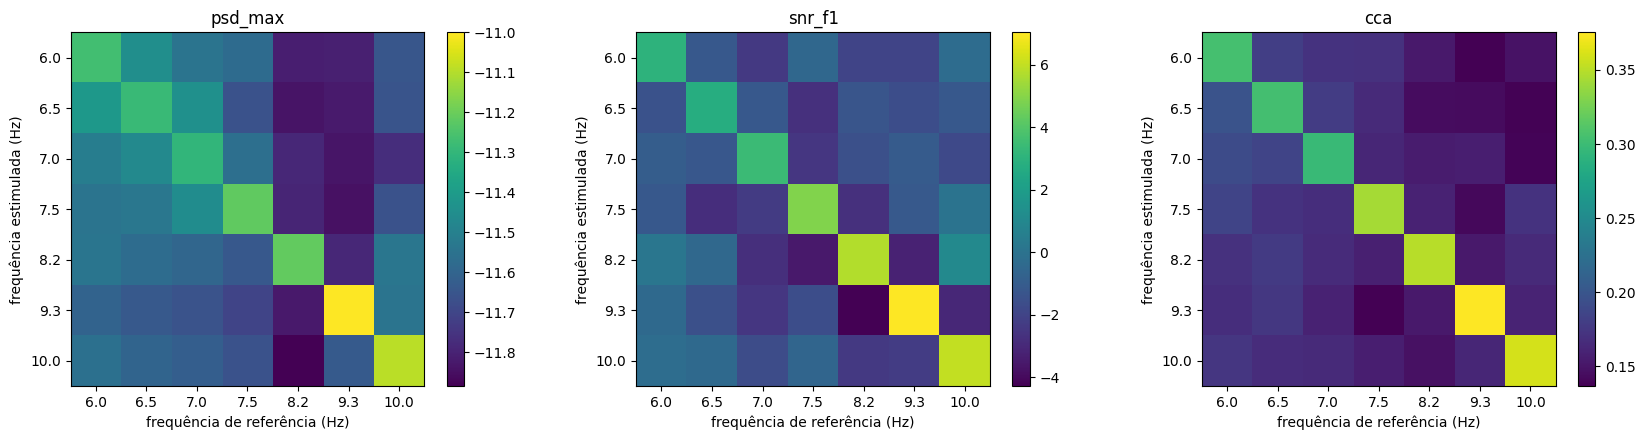

In [7]:
F = np.load('dados/single_caracteristicas.npy')
y = np.load('dados/single_epocas_meta.npy')[:, 0]

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))
for eixo, (tipo, desloc) in zip(eixos, (('psd_max', 0), ('snr_f1', 1), ('cca', 3))):
    M = np.array([F[y == alvo][:, desloc::4][:, :7].mean(axis=0) for alvo in FREQS])
    im = eixo.imshow(M, cmap='viridis')
    eixo.set_xticks(range(7), FREQS); eixo.set_yticks(range(7), FREQS)
    eixo.set_xlabel('frequência de referência (Hz)'); eixo.set_ylabel('frequência estimulada (Hz)')
    eixo.set_title(tipo); plt.colorbar(im, ax=eixo, fraction=.046)
plt.tight_layout(); plt.show()

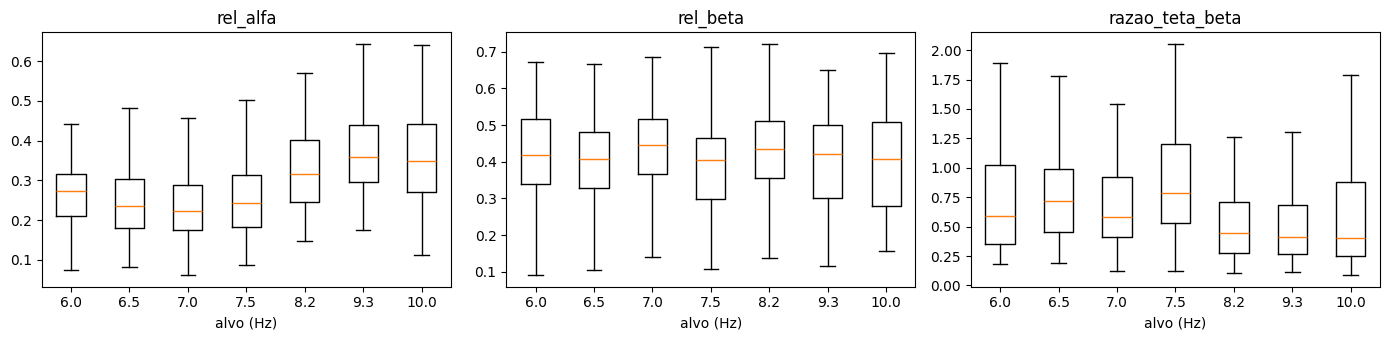

In [8]:
# distribuição dos ritmos por classe
rcParams['figure.figsize'] = [14., 3.5]
fig, eixos = plt.subplots(1, 3)
for eixo, col in zip(eixos, ('rel_alfa', 'rel_beta', 'razao_teta_beta')):
    j = NOMES.index(col)
    eixo.boxplot([F[y == alvo, j] for alvo in FREQS], showfliers=False)
    eixo.set_xticks(range(1, 8), FREQS); eixo.set_title(col); eixo.set_xlabel('alvo (Hz)')
plt.tight_layout(); plt.show()

- A diagonal aparece com clareza para as três características SSVEP, mais nítida no `cca`, que soma os harmônicos.
- A beta relativa praticamente **não muda com a frequência estimulada**. Já a alfa relativa sobe nos alvos de 8,2–10 Hz, e a TBR fica maior nos alvos de 6–7,5 Hz (teta mais alta), ambas por causa da contaminação descrita acima. Isso é esperado: beta e TBR medem o **estado** do participante (atenção), não **para onde** ele olha. O próximo notebook confirma isso na classificação, e o notebook 05 usa esses ritmos para o que eles medem de fato.